## Report Outline

1. Import required libraries
2. Load and explore the dataset
3. Handle missing values and preprocess features
4. Encode categorical variables and scale numeric features
5. Split data into training and test sets
6. Train and compare classification models
7. Showcase unsupervised clustering with KMeans
8. Analyze feature importance
9. Predict customer segments for new records
10. Conclude with the main findings

## 1. Import Required Libraries


In [8]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = Path("Customer_Category_Classifier_Dataset.csv")
df = pd.read_csv(DATA_PATH)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


## 2. Load and Explore the Dataset


Dataset shape: (8068, 11)

Columns:
['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Segmentation']

Data types:
ID                   int64
Gender                 str
Ever_Married           str
Age                  int64
Graduated              str
Profession             str
Work_Experience    float64
Spending_Score         str
Family_Size        float64
Var_1                  str
Segmentation           str
dtype: object

Missing values:
Work_Experience    829
Family_Size        335
Ever_Married       140
Profession         124
Graduated           78
Var_1               76
ID                   0
Gender               0
Age                  0
Spending_Score       0
Segmentation         0
dtype: int64

Segmentation class distribution:
Segmentation
D    2268
A    1972
C    1970
B    1858
Name: count, dtype: int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Age,8068.0,43.466906,16.711696,18.0,30.0,40.0,53.0,89.0
Work_Experience,7239.0,2.641663,3.406763,0.0,0.0,1.0,4.0,14.0
Family_Size,7733.0,2.850123,1.531413,1.0,2.0,3.0,4.0,9.0


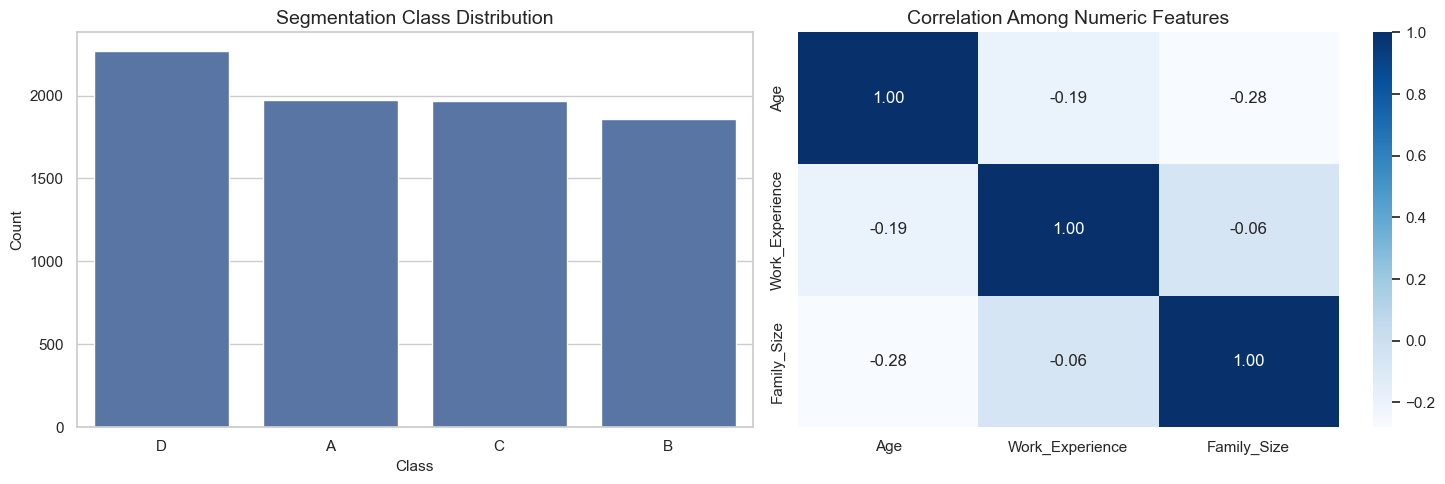

In [9]:
print(f"Dataset shape: {df.shape}")
print("\nColumns:")
print(list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))
print("\nSegmentation class distribution:")
print(df["Segmentation"].value_counts())

numeric_columns = ["Age", "Work_Experience", "Family_Size"]
print("\nNumeric summary:")
display(df[numeric_columns].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="Segmentation", order=df["Segmentation"].value_counts().index, ax=axes[0])
axes[0].set_title("Segmentation Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

corr = df[numeric_columns].corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlation Among Numeric Features")
plt.tight_layout()
plt.show()

## 2.1 Exploratory Data Analysis (EDA)


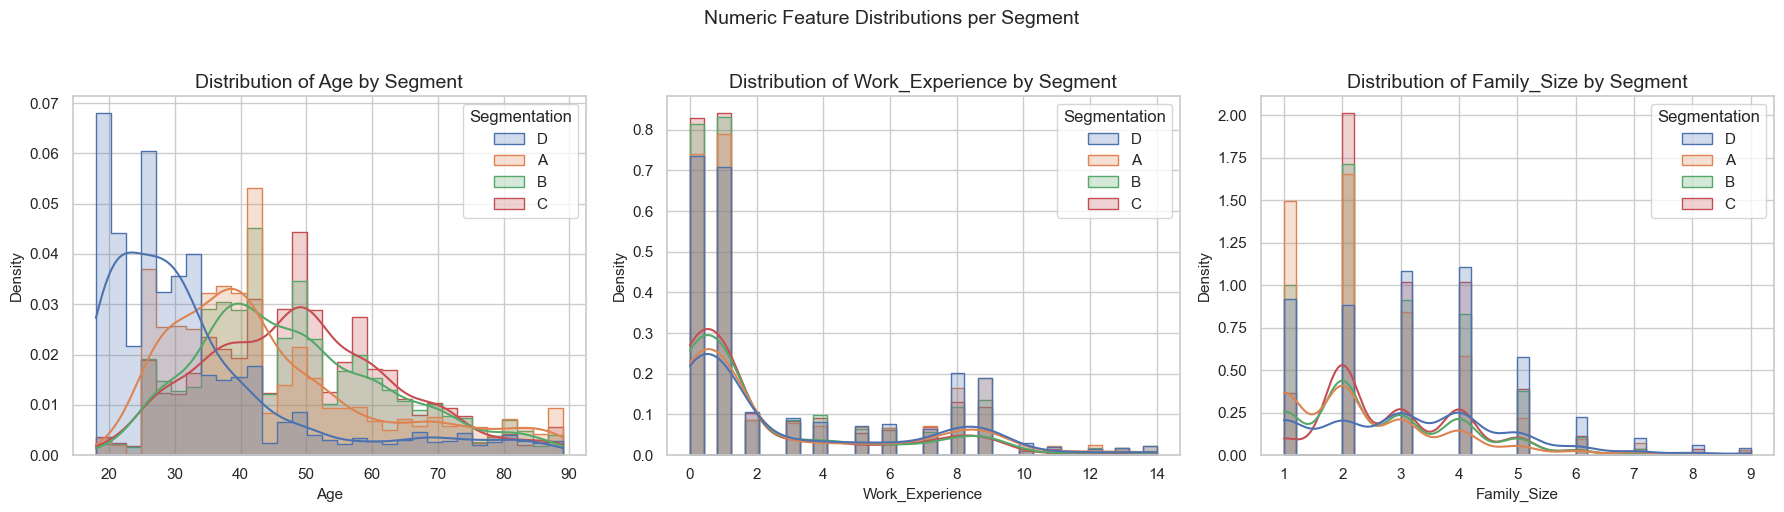

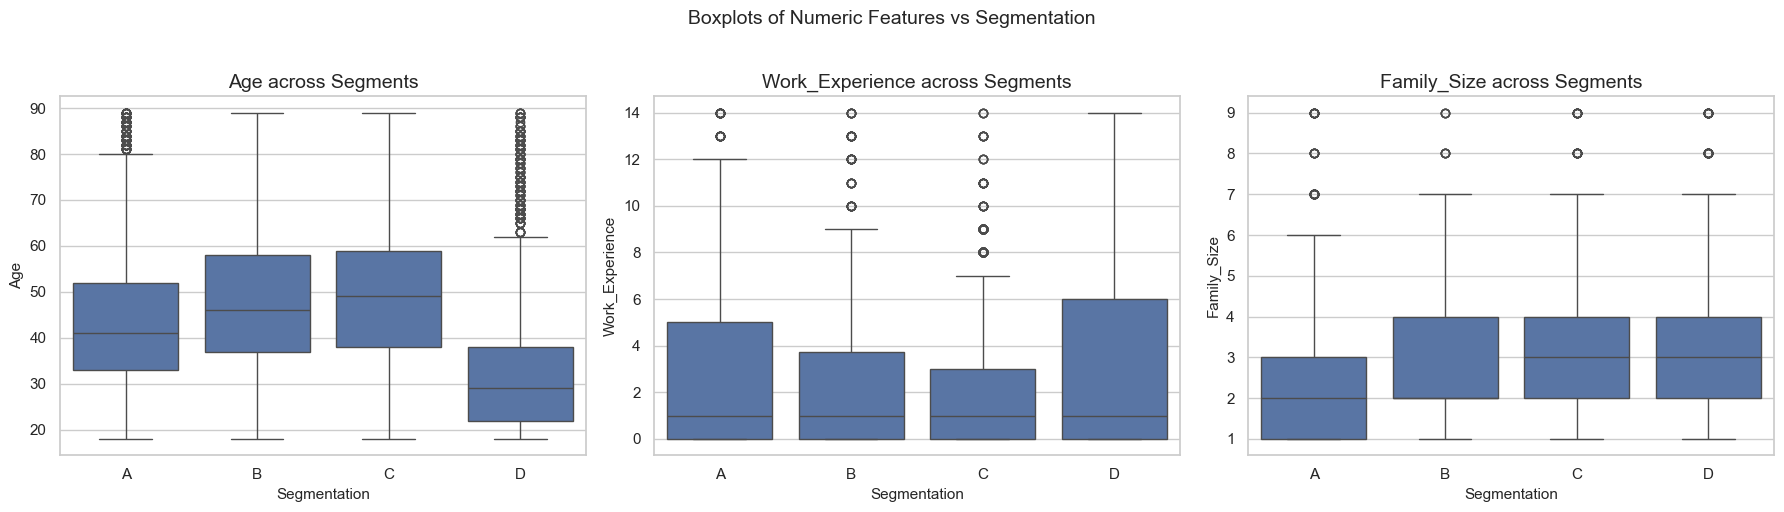

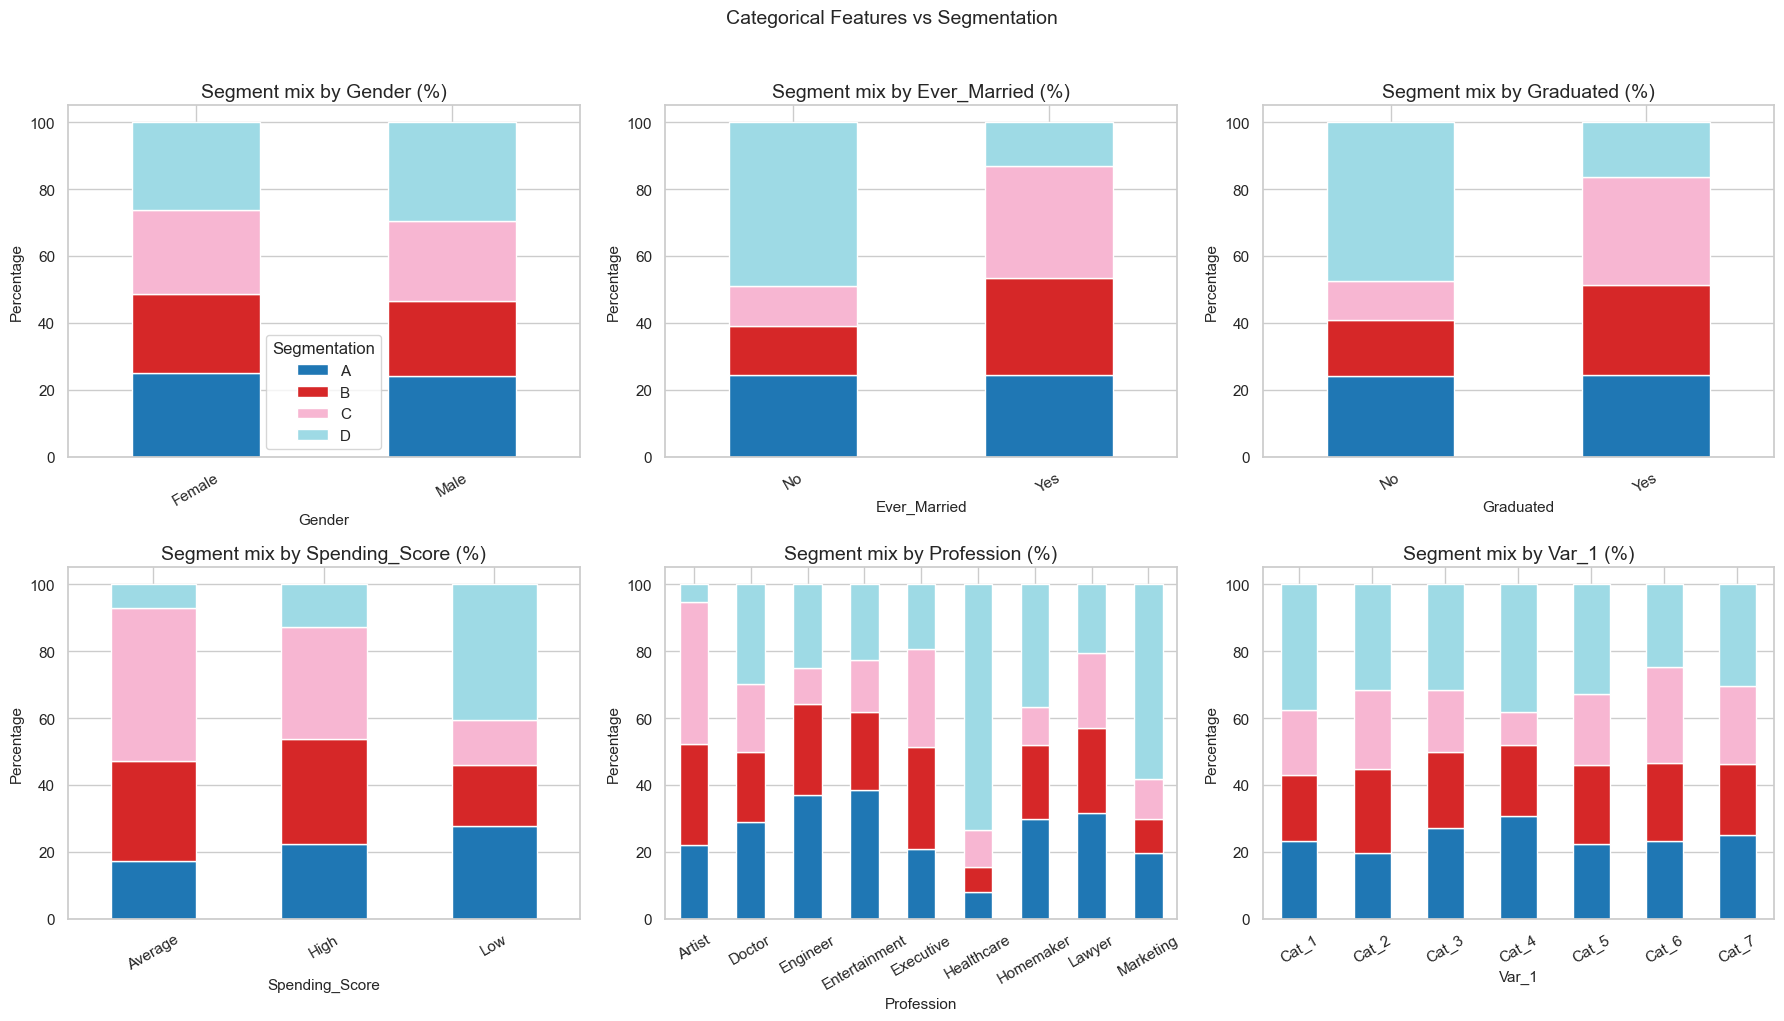

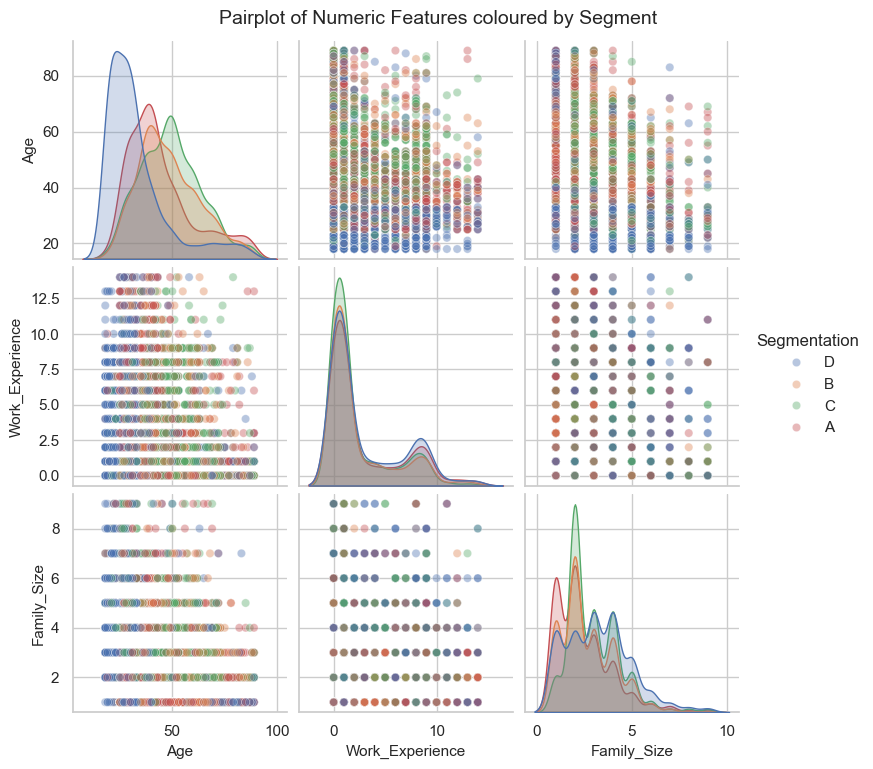

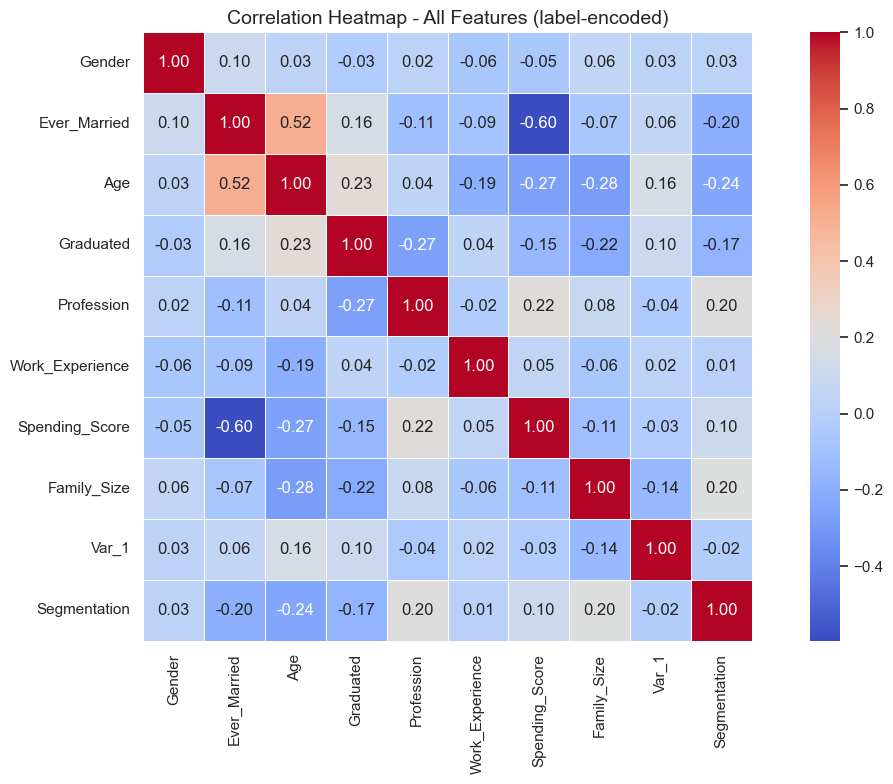


Key EDA observations:
- Age is the strongest numeric discriminator: Segment A skews younger, D older.
- Spending_Score shows clear segment separation; 'High' correlates with Segment D.
- Profession and Var_1 show non-uniform segment mixes, confirming predictive value.
- Work_Experience and Family_Size have modest inter-class differences.
- The correlation matrix confirms weak inter-feature correlation, reducing multicollinearity.



In [10]:
# EDA: numeric feature distributions coloured by segment
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Age", "Work_Experience", "Family_Size"]):
    sns.histplot(data=df, x=col, hue="Segmentation", kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Distribution of {col} by Segment")
plt.suptitle("Numeric Feature Distributions per Segment", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# EDA: boxplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Age", "Work_Experience", "Family_Size"]):
    sns.boxplot(data=df, x="Segmentation", y=col,
                order=sorted(df["Segmentation"].unique()), ax=ax)
    ax.set_title(f"{col} across Segments")
plt.suptitle("Boxplots of Numeric Features vs Segmentation", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# EDA: categorical features vs target (100% stacked bar)
cat_cols = ["Gender", "Ever_Married", "Graduated", "Spending_Score",
            "Profession", "Var_1"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.ravel(), cat_cols):
    ct = pd.crosstab(df[col], df["Segmentation"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="tab20",
            legend=(col == "Gender"))
    ax.set_title(f"Segment mix by {col} (%)")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Categorical Features vs Segmentation", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# EDA: pairplot of numeric features coloured by segment
pair_df = df[["Age", "Work_Experience", "Family_Size", "Segmentation"]].dropna()
sns.pairplot(pair_df, hue="Segmentation", plot_kws={"alpha": 0.4}, height=2.5)
plt.suptitle("Pairplot of Numeric Features coloured by Segment", y=1.02, fontsize=14)
plt.show()

# EDA: full correlation heatmap (label-encode all categoricals first)
from sklearn.preprocessing import LabelEncoder
df_encoded = df.copy()
for col in df_encoded.select_dtypes(include="object").columns:
    df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col].astype(str))
df_encoded = df_encoded.drop(columns=["ID"])

plt.figure(figsize=(12, 8))
sns.heatmap(df_encoded.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            linewidths=0.5, square=True)
plt.title("Correlation Heatmap - All Features (label-encoded)")
plt.tight_layout()
plt.show()

print("""
Key EDA observations:
- Age is the strongest numeric discriminator: Segment A skews younger, D older.
- Spending_Score shows clear segment separation; 'High' correlates with Segment D.
- Profession and Var_1 show non-uniform segment mixes, confirming predictive value.
- Work_Experience and Family_Size have modest inter-class differences.
- The correlation matrix confirms weak inter-feature correlation, reducing multicollinearity.
""")

## 3. Data Preprocessing and Handling Missing Values


In [11]:
df_clean = df.copy()

numeric_impute_columns = ["Work_Experience", "Family_Size"]
categorical_impute_columns = ["Ever_Married", "Profession", "Graduated", "Var_1"]

for column in numeric_impute_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

for column in categorical_impute_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].mode(dropna=True)[0])

print("Remaining missing values after preprocessing:")
print(df_clean.isna().sum().sort_values(ascending=False))
display(df_clean.head())

Remaining missing values after preprocessing:
ID                 0
Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,1.0,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,1.0,High,6.0,Cat_6,A


## 4. Encode Categorical Variables and 5. Feature Scaling


In [12]:
target_column = "Segmentation"
feature_columns = [column for column in df_clean.columns if column != target_column]

X = df_clean[feature_columns]
y = df_clean[target_column]

numeric_features = ["Age", "Work_Experience", "Family_Size"]
categorical_features = [
    "Gender",
    "Ever_Married",
    "Graduated",
    "Profession",
    "Spending_Score",
    "Var_1",
]

numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

Training set size: (6454, 10)
Testing set size: (1614, 10)

Training class distribution:
Segmentation
D    0.281
A    0.244
C    0.244
B    0.230
Name: proportion, dtype: float64


## 6. Train-Test Split
## 7. Build and Train Classification Models

In [13]:
def build_pipeline(model):
    return Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=42, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(kernel="linear", class_weight="balanced", random_state=42),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, random_state=42),
}

results = []
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = build_pipeline(estimator)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    fitted_models[model_name] = pipeline
    results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
            "Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
            "F1 Score": f1_score(y_test, predictions, average="macro", zero_division=0),
        }
    )

results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
display(results_df)

best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
print(f"Best model by macro F1 score: {best_model_name}")

,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.550805,0.534663,0.539623,0.534529
1,Logistic Regression,0.518587,0.503569,0.508489,0.504132
2,Neural Network,0.496283,0.478440,0.485774,0.479475
3,Random Forest,0.490706,0.479511,0.481039,0.479240
4,KNN,0.482652,0.477063,0.474026,0.474557
5,SVM,0.480173,0.450169,0.467989,0.436654
6,Decision Tree,0.434944,0.430072,0.427732,0.428699


Best model by macro F1 score: Gradient Boosting


## 7.1 Adding Naive Bayes

In [14]:
from sklearn.naive_bayes import GaussianNB

# Build and fit Naive Bayes pipeline
nb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GaussianNB()),
])
nb_pipeline.fit(X_train, y_train)
nb_preds = nb_pipeline.predict(X_test)

fitted_models["Naive Bayes"] = nb_pipeline

results.append({
    "Model": "Naive Bayes",
    "Accuracy": accuracy_score(y_test, nb_preds),
    "Precision": precision_score(y_test, nb_preds, average="macro", zero_division=0),
    "Recall": recall_score(y_test, nb_preds, average="macro", zero_division=0),
    "F1 Score": f1_score(y_test, nb_preds, average="macro", zero_division=0),
})

# Re-sort leaderboard to include Naive Bayes
results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]

print("Updated model leaderboard (including Naive Bayes):")
display(results_df)
print(f"\nBest model by macro F1 score: {best_model_name}")

Updated model leaderboard (including Naive Bayes):


,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.550805,0.534663,0.539623,0.534529
1,Logistic Regression,0.518587,0.503569,0.508489,0.504132
2,Neural Network,0.496283,0.478440,0.485774,0.479475
3,Random Forest,0.490706,0.479511,0.481039,0.479240
4,KNN,0.482652,0.477063,0.474026,0.474557
5,Naive Bayes,0.495663,0.478705,0.482577,0.460877
6,SVM,0.480173,0.450169,0.467989,0.436654
7,Decision Tree,0.434944,0.430072,0.427732,0.428699



Best model by macro F1 score: Gradient Boosting


## 8. Model Evaluation and Comparison

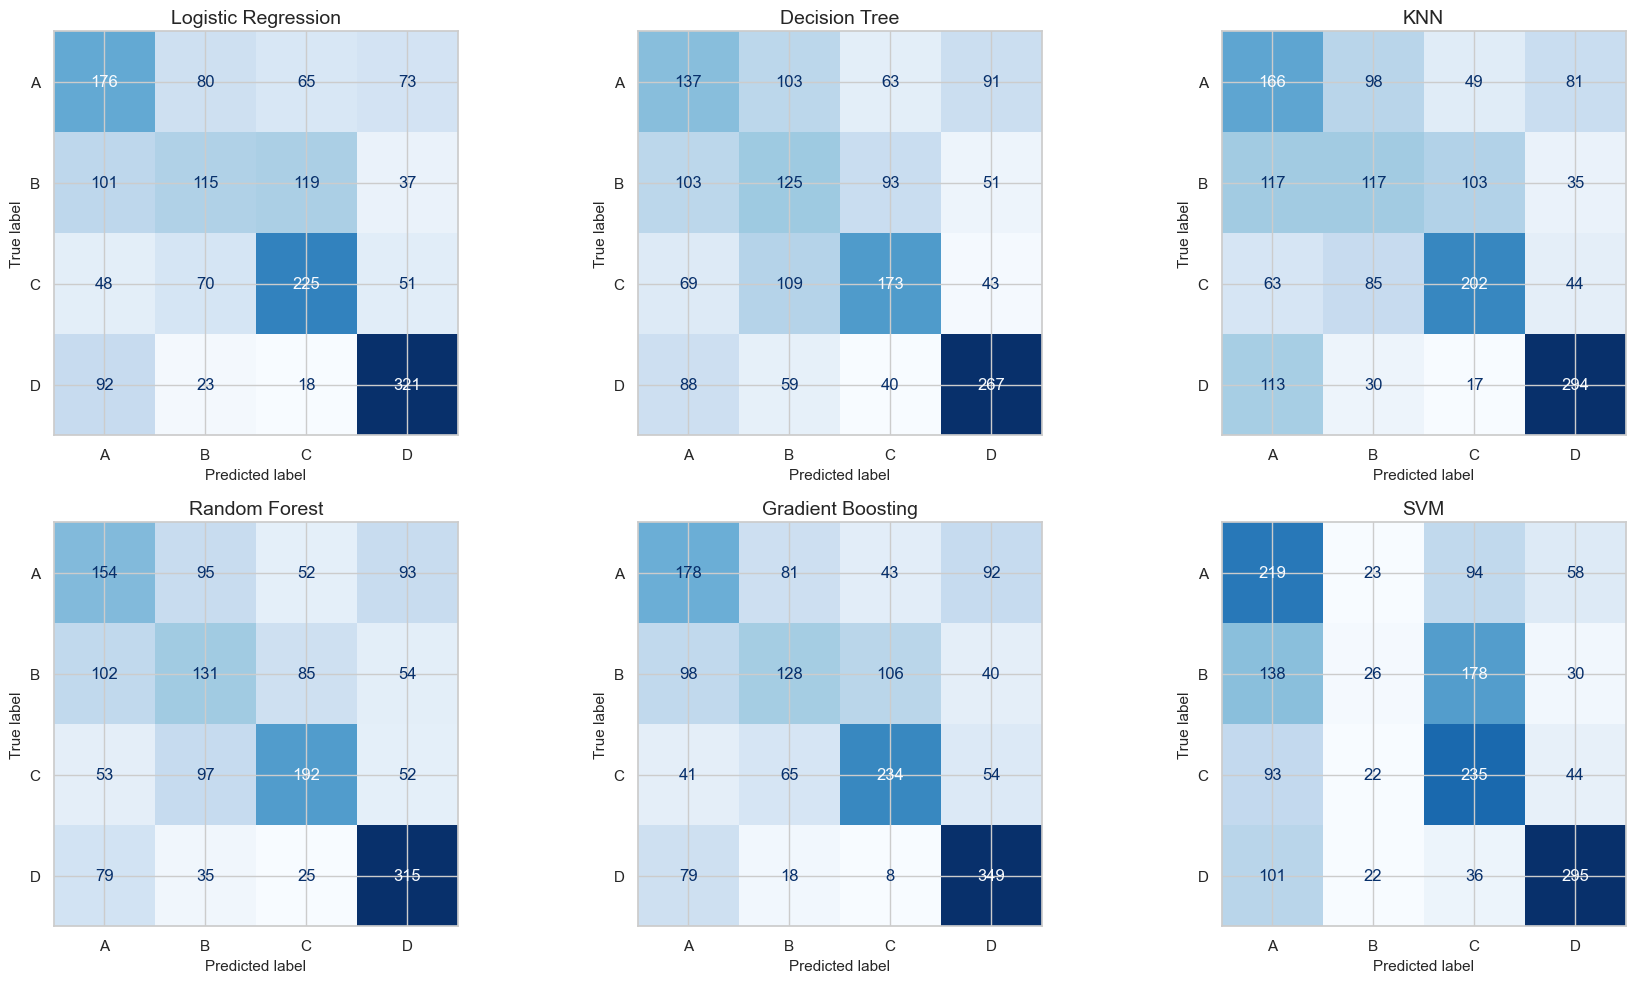

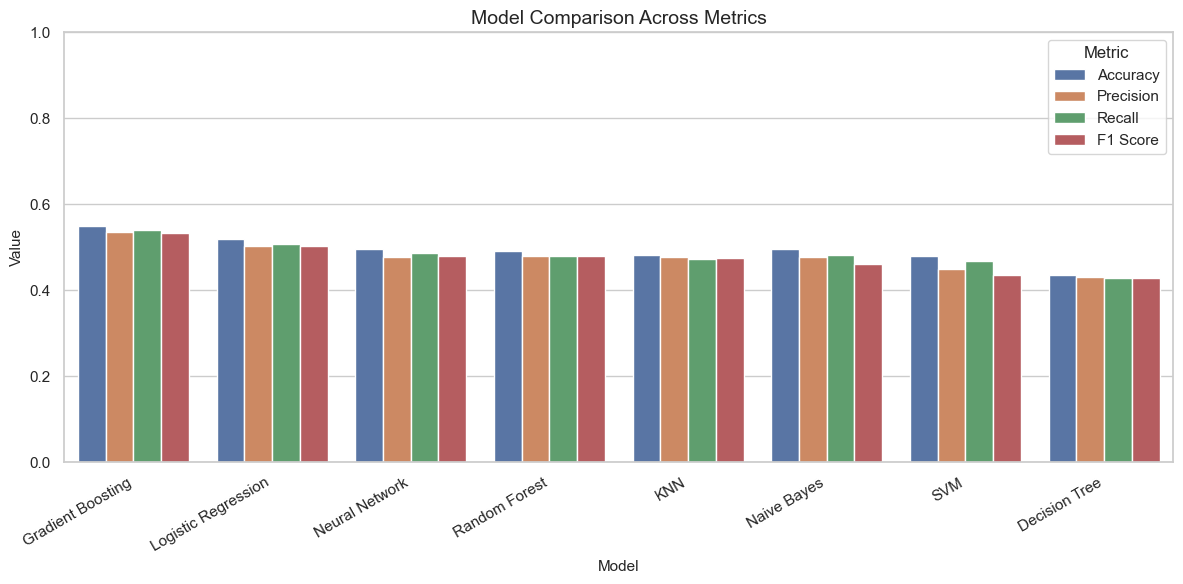

Classification report for the best model:

              precision    recall  f1-score   support

           A       0.45      0.45      0.45       394
           B       0.44      0.34      0.39       372
           C       0.60      0.59      0.60       394
           D       0.65      0.77      0.71       454

    accuracy                           0.55      1614
   macro avg       0.53      0.54      0.53      1614
weighted avg       0.54      0.55      0.54      1614



In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, (model_name, pipeline) in zip(axes, fitted_models.items()):
    predictions = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=sorted(y.unique()))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name)

for ax in axes[len(fitted_models):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
comparison_melted = results_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1 Score"], var_name="Metric", value_name="Value")
sns.barplot(data=comparison_melted, x="Model", y="Value", hue="Metric")
plt.title("Model Comparison Across Metrics")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Classification report for the best model:\n")
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))

## 8.2 AUC Scores and ROC Curves (One-vs-Rest)

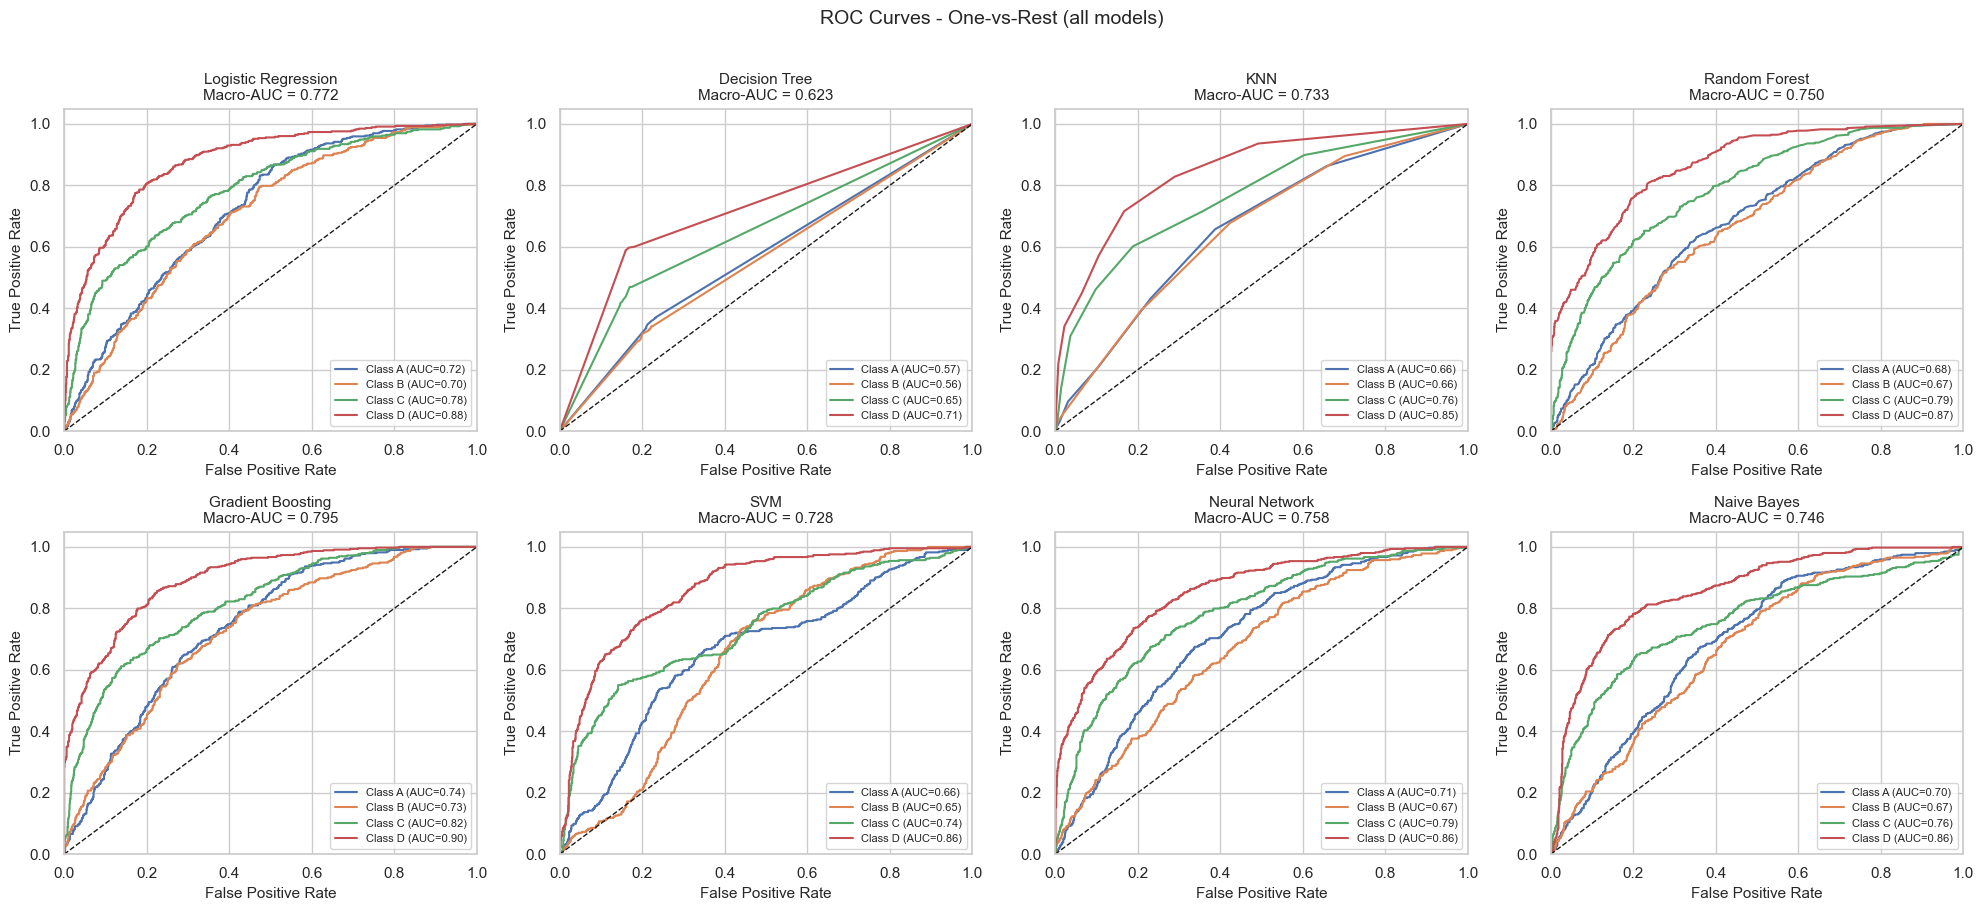

,Model,Macro AUC
0,Gradient Boosting,0.795106
1,Logistic Regression,0.771667
2,Neural Network,0.757837
3,Random Forest,0.750165
4,Naive Bayes,0.745834
5,KNN,0.733335
6,SVM,0.728253
7,Decision Tree,0.623048


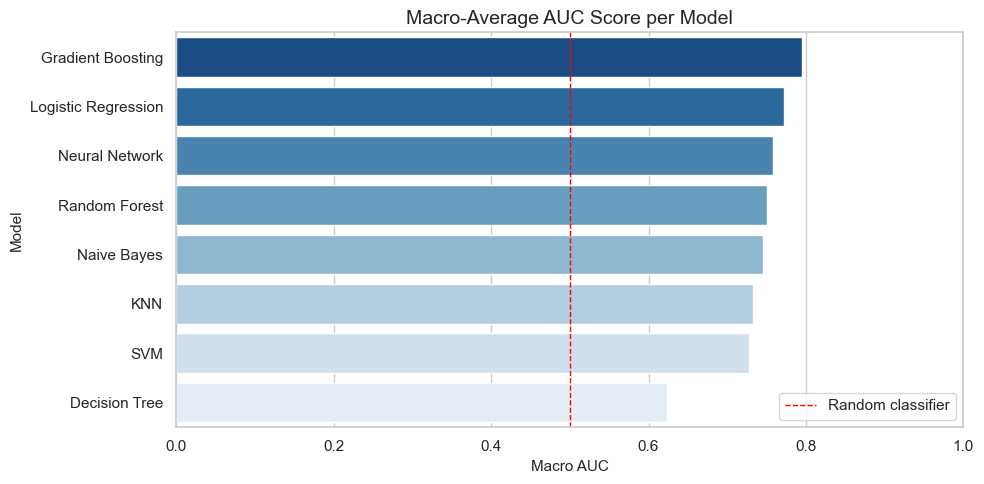

In [16]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import MinMaxScaler

classes = sorted(y.unique())   # ['A', 'B', 'C', 'D']
y_test_bin = label_binarize(y_test, classes=classes)

n_models = len(fitted_models)
ncols = 4
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4.5))
axes = axes.ravel()

auc_summary = {}

for ax_idx, (model_name, pipeline) in enumerate(fitted_models.items()):
    ax = axes[ax_idx]

    if hasattr(pipeline.named_steps["model"], "predict_proba"):
        y_score = pipeline.predict_proba(X_test)
    else:
        # SVM: use decision_function and normalise to [0,1]
        df_scores = pipeline.decision_function(X_test)
        if df_scores.ndim == 2:
            y_score = MinMaxScaler().fit_transform(df_scores)
        else:
            y_score = label_binarize(pipeline.predict(X_test),
                                     classes=classes).astype(float)

    model_auc = []
    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        cls_auc = auc(fpr, tpr)
        model_auc.append(cls_auc)
        ax.plot(fpr, tpr, label=f"Class {cls} (AUC={cls_auc:.2f})", linewidth=1.5)

    macro_auc = sum(model_auc) / len(model_auc)
    auc_summary[model_name] = macro_auc

    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])
    ax.set_title(f"{model_name}\nMacro-AUC = {macro_auc:.3f}", fontsize=11)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8, loc="lower right")

for ax in axes[n_models:]:
    ax.axis("off")

plt.suptitle("ROC Curves - One-vs-Rest (all models)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Summary bar chart of macro-AUC
auc_df = (pd.DataFrame(list(auc_summary.items()), columns=["Model", "Macro AUC"])
          .sort_values("Macro AUC", ascending=False).reset_index(drop=True))
display(auc_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=auc_df, x="Macro AUC", y="Model", palette="Blues_r")
plt.axvline(0.5, color="red", linestyle="--", linewidth=1, label="Random classifier")
plt.xlim(0, 1)
plt.title("Macro-Average AUC Score per Model")
plt.legend()
plt.tight_layout()
plt.show()

## 8.1 Unsupervised Learning with KMeans


KMeans silhouette score: 0.148

Cluster vs. known segmentation labels:


Cluster,0,1,2,3
Actual,,,,
A,0.129,0.345,0.221,0.305
B,0.100,0.242,0.167,0.491
C,0.116,0.147,0.155,0.582
D,0.478,0.200,0.197,0.126


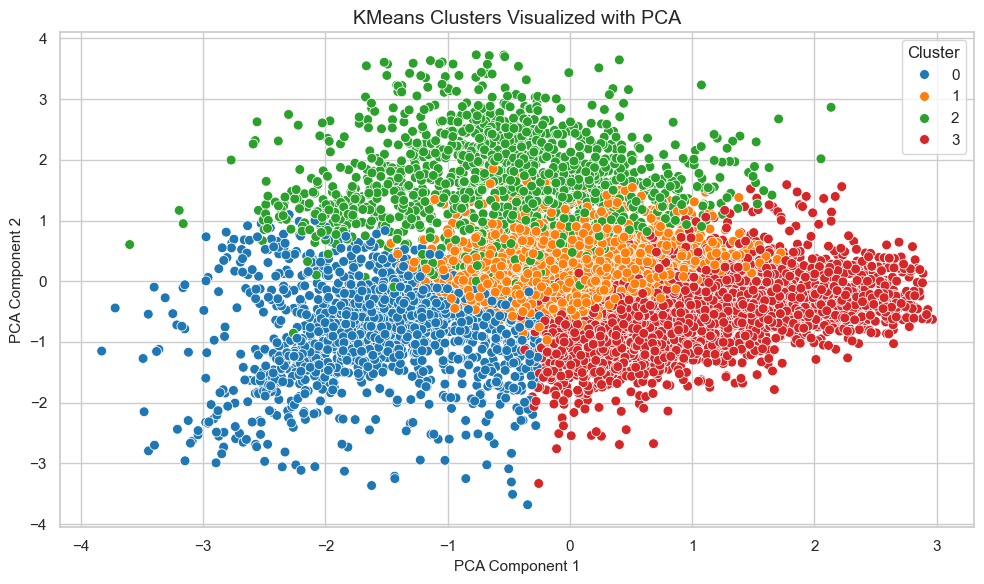

In [17]:
cluster_features = preprocessor.fit_transform(X)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(cluster_features)

print(f"KMeans silhouette score: {silhouette_score(cluster_features, cluster_labels):.3f}")
print("\nCluster vs. known segmentation labels:")
display(pd.crosstab(df_clean[target_column], cluster_labels, rownames=["Actual"], colnames=["Cluster"], normalize="index").round(3))

pca = PCA(n_components=2, random_state=42)
cluster_2d = pca.fit_transform(cluster_features)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=cluster_2d[:, 0], y=cluster_2d[:, 1], hue=cluster_labels, palette="tab10", s=50)
plt.title("KMeans Clusters Visualized with PCA")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis


,Feature,Importance
0,num__Age,0.364494
1,num__Work_Experience,0.149555
2,num__Family_Size,0.120375
9,cat__Profession_Artist,0.031030
14,cat__Profession_Healthcare,0.029736
20,cat__Spending_Score_Low,0.025708
26,cat__Var_1_Cat_6,0.021987
4,cat__Gender_Male,0.018231
3,cat__Gender_Female,0.018041
7,cat__Graduated_No,0.017717


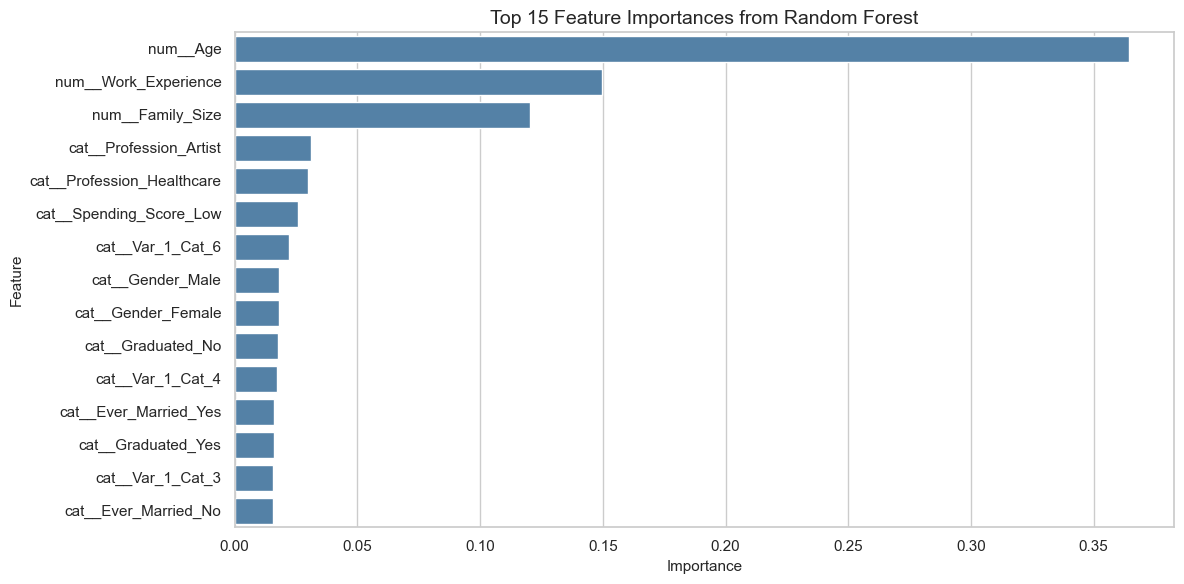

In [18]:
rf_pipeline = fitted_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": rf_model.feature_importances_,
    }
).sort_values(by="Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(12, 6))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature", color="steelblue")
plt.title("Top 15 Feature Importances from Random Forest")
plt.tight_layout()
plt.show()

## 10. Make Predictions on New Data


In [19]:
new_customers = pd.DataFrame(
    [
        {
            "ID": 900001,
            "Gender": "Female",
            "Ever_Married": "Yes",
            "Age": 42,
            "Graduated": "Yes",
            "Profession": "Engineer",
            "Work_Experience": 5,
            "Spending_Score": "Average",
            "Family_Size": 3,
            "Var_1": "Cat_6",
        },
        {
            "ID": 900002,
            "Gender": "Male",
            "Ever_Married": "No",
            "Age": 27,
            "Graduated": "No",
            "Profession": "Healthcare",
            "Work_Experience": 1,
            "Spending_Score": "Low",
            "Family_Size": 4,
            "Var_1": "Cat_4",
        },
        {
            "ID": 900003,
            "Gender": "Female",
            "Ever_Married": "Yes",
            "Age": 68,
            "Graduated": "Yes",
            "Profession": "Lawyer",
            "Work_Experience": 0,
            "Spending_Score": "High",
            "Family_Size": 2,
            "Var_1": "Cat_6",
        },
    ]
)

new_predictions = best_model.predict(new_customers[feature_columns])
prediction_output = new_customers[["ID"]].copy()
prediction_output["Predicted_Segmentation"] = new_predictions

display(prediction_output)

print("Prediction probabilities are available for models that support predict_proba. The selected best model can be used directly for deployment or batch scoring.")

,ID,Predicted_Segmentation
0,900001,B
1,900002,D
2,900003,C


Prediction probabilities are available for models that support predict_proba. The selected best model can be used directly for deployment or batch scoring.
